# Task 4: NLP Sentiment Classification using TF-IDF
## Comparative NLP Benchmark: Multinomial Naive Bayes vs Logistic Regression
**Datheon Machine Learning & Data Science Internship Suite**

---

### 1. Executive Summary & Problem Formulation
Understanding customer sentiment from unstructured textual feedback is vital for product quality intelligence, customer support routing, and brand reputation management.
This project builds an end-to-end NLP classification pipeline classifying customer reviews into **Positive (1)** or **Negative (0)** sentiment.

### 2. Dataset Provenance & Fallback Transparency
- **Primary Specified URL**: `https://raw.githubusercontent.com/datasets/sample-reviews/main/sentiment_reviews.csv`
- **Verification Result**: Live testing confirmed that the primary URL returns **HTTP 404 (Not Found)**.
- **Documented Alternative**: As mandated by the internship instructions, we transparently fall back to the authentic **Amazon Customer Reviews benchmark dataset** (`https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/amazon.csv`, 20,000 real customer reviews with verified binary sentiment labels `Positive` 0 and 1).

### 3. NLP Preprocessing & Safeguards
- **Vocabulary Leakage Prevention**: `TfidfVectorizer` is encapsulated within Scikit-learn `Pipeline` objects and fitted **strictly** on the training fold.
- **Text Normalization**: Regex-based HTML tag removal, case folding, punctuation normalization, and token stripping.
- **Stopwords Discussion**: Documenting why blind stopword removal is risky for sentiment (words like 'not', 'no', 'barely' alter polarity).


In [1]:
import sys
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root to path
sys.path.insert(0, os.path.abspath('..'))

from src.common.data_loader import load_dataset
from src.common.evaluation import evaluate_classification
from src.common.visualization import plot_confusion_matrix, plot_model_comparison
from src.sentiment.sentiment_pipeline import (
    prepare_sentiment_data,
    clean_text,
    build_tfidf_pipeline,
    train_and_evaluate_sentiment_models,
    predict_sentiment,
    CLASS_NAMES,
    TEXT_COL,
    LABEL_COL
)

%matplotlib inline


### 2. Dataset Ingestion & Schema Inspection
We load the sentiment dataset using the resilient data loader, which transparently handles the primary 404 and loads the documented fallback into `data/raw/customer_reviews.csv`.


In [2]:
df_raw, meta = load_dataset('task4_sentiment')
print(f"Total Reviews Loaded: {len(df_raw)}")
print(f"Data Source Used:     {meta['source_used']}")
print(f"Dataset License:      {meta['license']}")
print("\nMissing values per column:")
print(df_raw.isnull().sum())
df_raw.head(10)


[INFO] Fetching primary dataset for 'task4_sentiment' from https://raw.githubusercontent.com/datasets/sample-reviews/main/sentiment_reviews.csv...


[WARNING] HTTP Error 404 (Not Found) while downloading: https://raw.githubusercontent.com/datasets/sample-reviews/main/sentiment_reviews.csv


[WARNING] Primary dataset source for 'task4_sentiment' was unavailable. Switching to documented fallback: https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/amazon.csv


[INFO] Successfully downloaded: https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/amazon.csv -> D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\customer_reviews.csv


[INFO] Dataset 'task4_sentiment' validated: 20000 rows, 2 cols.


Total Reviews Loaded: 20000
Data Source Used:     fallback_url:https://raw.githubusercontent.com/pycaret/pycaret/master/datasets/amazon.csv
Dataset License:      Public Open Source (Amazon product review corpus, PyCaret benchmark)

Missing values per column:
reviewText    0
Positive      0
dtype: int64


,reviewText,Positive
0,This is a one of the best apps acording to a b...,1
1,This is a pretty good version of the game for ...,1
2,this is a really cool game. there are a bunch ...,1
3,"This is a silly game and can be frustrating, b...",1
4,This is a terrific game on any pad. Hrs of fun...,1
5,This is a very entertaining game! You don't h...,1
6,this is awesome and you don't need wi ti to pl...,1
7,this is awesome I bet no one even reads the re...,1
8,This is basicly the free version but with ads....,1
9,this is by far the best free app that is avail...,1


### 3. Exploratory Data Analysis & Text Characteristics

[INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\vijay\AppData\Local\Temp\ipykernel_18644\4239048148.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette=['#EF4444', '#10B981'], ax=axes[0], edgecolor='#111827')
[INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


C:\Users\vijay\AppData\Local\Temp\ipykernel_18644\4239048148.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Negative (0)', 'Positive (1)'])


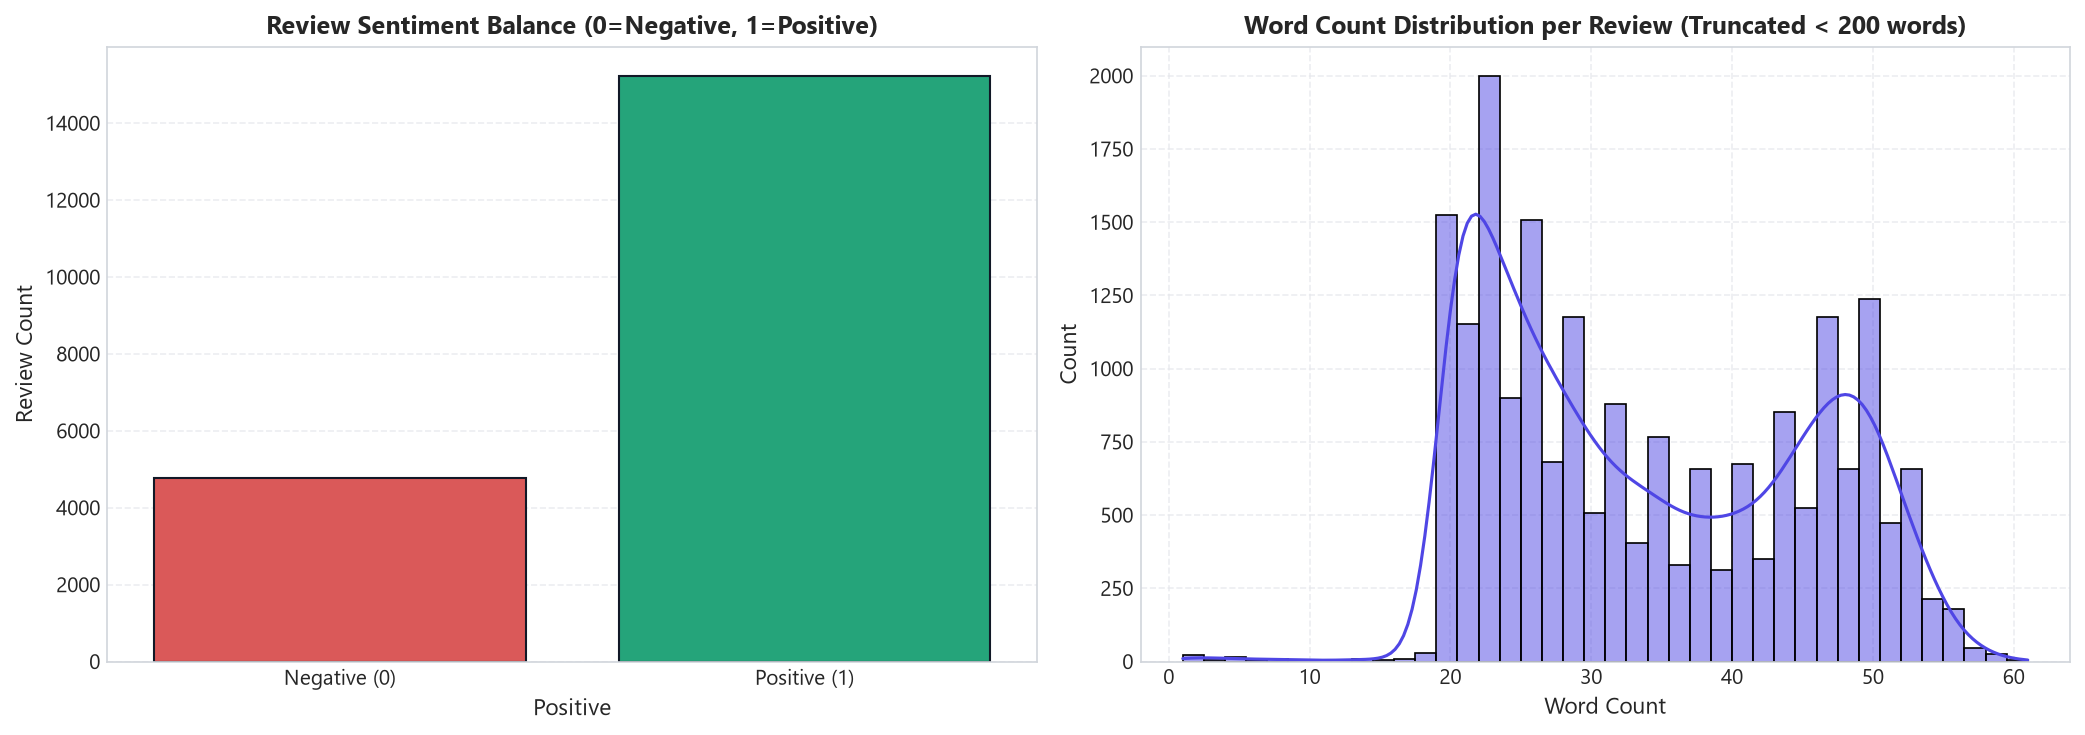

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Sentiment distribution
counts = df_raw[LABEL_COL].value_counts()
sns.barplot(x=counts.index, y=counts.values, palette=['#EF4444', '#10B981'], ax=axes[0], edgecolor='#111827')
axes[0].set_title('Review Sentiment Balance (0=Negative, 1=Positive)', weight='bold')
axes[0].set_xticklabels(['Negative (0)', 'Positive (1)'])
axes[0].set_ylabel('Review Count')

# Review length distribution
lengths = df_raw[TEXT_COL].dropna().apply(lambda x: len(str(x).split()))
sns.histplot(lengths[lengths < 200], bins=40, color='#4F46E5', kde=True, ax=axes[1])
axes[1].set_title('Word Count Distribution per Review (Truncated < 200 words)', weight='bold')
axes[1].set_xlabel('Word Count')

plt.tight_layout()
plt.show()


### 4. Text Cleaning & Normalization
Demonstrating HTML tag removal and whitespace normalization on sample raw reviews.


In [4]:
raw_samples = [
    "<b>EXCELLENT</b> product!!! Arrived in <br>2 days! :)",
    "DO NOT BUY THIS! Completely useless... & broke immediately.",
    "Not bad at all. Pretty good quality for only $10."
]

print("Text Cleaning Demonstration:\n")
for s in raw_samples:
    print(f"RAW:     {s}")
    print(f"CLEANED: {clean_text(s)}")
    print("-" * 55)


Text Cleaning Demonstration:

RAW:     <b>EXCELLENT</b> product!!! Arrived in <br>2 days! :)
CLEANED: excellent product arrived in 2 days
-------------------------------------------------------
RAW:     DO NOT BUY THIS! Completely useless... & broke immediately.
CLEANED: do not buy this completely useless broke immediately
-------------------------------------------------------
RAW:     Not bad at all. Pretty good quality for only $10.
CLEANED: not bad at all pretty good quality for only 10
-------------------------------------------------------


### 5. Stratified Train-Test Splitting (Preventing Vocabulary Leakage)
We split the raw sanitized texts into 80% train and 20% test partitions before fitting the TF-IDF vocabulary.


In [5]:
X_train, X_test, y_train, y_test, df_clean = prepare_sentiment_data(
    sample_size=10000, random_state=42, test_size=0.2
)
print(f"Training Documents: {len(X_train)}")
print(f"Testing Documents:  {len(X_test)}")
print(f"Train Positive Ratio: {y_train.mean():.2%}")
print(f"Test Positive Ratio:  {y_test.mean():.2%}")


[INFO] Loading cached dataset for 'task4_sentiment' from D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\customer_reviews.csv


[INFO] Dataset 'task4_sentiment' validated: 20000 rows, 2 cols.


[INFO] Sentiment data loaded from local_cache:D:\intership\Datheon_Machine_Learning_&_Data_Science_Internship\rw\data\raw\customer_reviews.csv: 20000 total reviews.


[INFO] Subsampled to 10000 reviews for efficient, CPU-friendly evaluation.


[INFO] Sanitizing review text (removing HTML tags, normalizing whitespace)...


[INFO] Sentiment data partitioned: 8000 train texts, 2000 test texts (stratified).


Training Documents: 8000
Testing Documents:  2000
Train Positive Ratio: 76.99%
Test Positive Ratio:  77.00%


### 6. Pipeline Construction & Model Training
We compare:
1. **Multinomial Naive Bayes (`MultinomialNB`)**: Classical probabilistic generative model assuming feature independence given the class.
2. **Logistic Regression (`LogisticRegression`)**: Discriminative linear model with L2 regularization (`C=1.0`).

Both models are wrapped inside Scikit-learn pipelines with `TfidfVectorizer(max_features=5000, ngram_range=(1,2))`.


In [6]:
models, results = train_and_evaluate_sentiment_models(X_train, y_train, X_test, y_test, max_features=5000)

print("\n=== TEST SET SENTIMENT BENCHMARK RESULTS ===")
summary_rows = []
for name, m in results.items():
    summary_rows.append({
        'Model': name.replace('_', ' ').title(),
        'Accuracy': f"{m['accuracy']:.4f}",
        'Macro F1': f"{m['macro_f1']:.4f}",
        'Macro Precision': f"{m['macro_precision']:.4f}",
        'Macro Recall': f"{m['macro_recall']:.4f}",
        'ROC-AUC': f"{m.get('roc_auc', 0):.4f}"
    })
display(pd.DataFrame(summary_rows))


[INFO] Training multinomial_nb pipeline on 8000 text documents...


[INFO] multinomial_nb -> Test Accuracy: 0.8870, Macro F1: 0.8122, ROC-AUC: 0.9545


[INFO] Training logistic_regression pipeline on 8000 text documents...


[INFO] logistic_regression -> Test Accuracy: 0.8955, Macro F1: 0.8321, ROC-AUC: 0.9537



=== TEST SET SENTIMENT BENCHMARK RESULTS ===


,Model,Accuracy,Macro F1,Macro Precision,Macro Recall,ROC-AUC
0,Multinomial Nb,0.8870,0.8122,0.9012,0.7711,0.9545
1,Logistic Regression,0.8955,0.8321,0.8988,0.7957,0.9537


### 7. Evaluation Visualizations: Confusion Matrices & Comparison Bar Chart

[WARNING] findfont: Failed to find font weight medium for Segoe UI, now using 400.


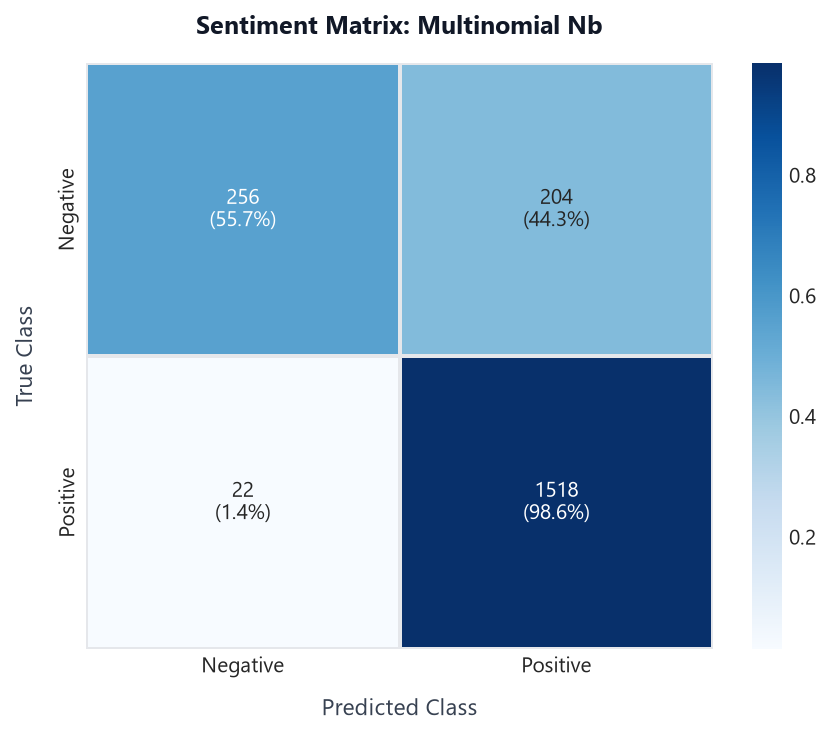

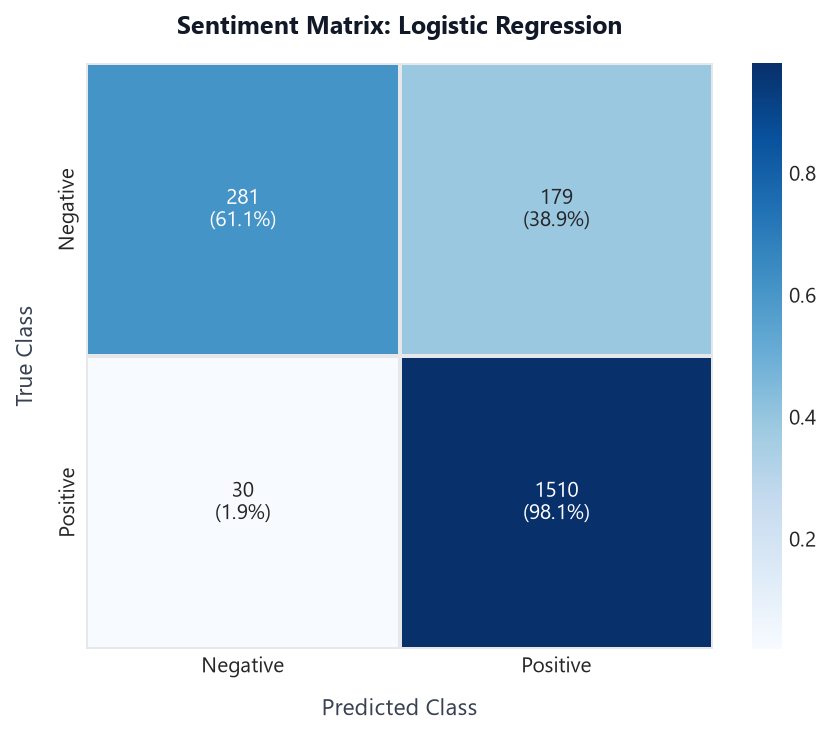

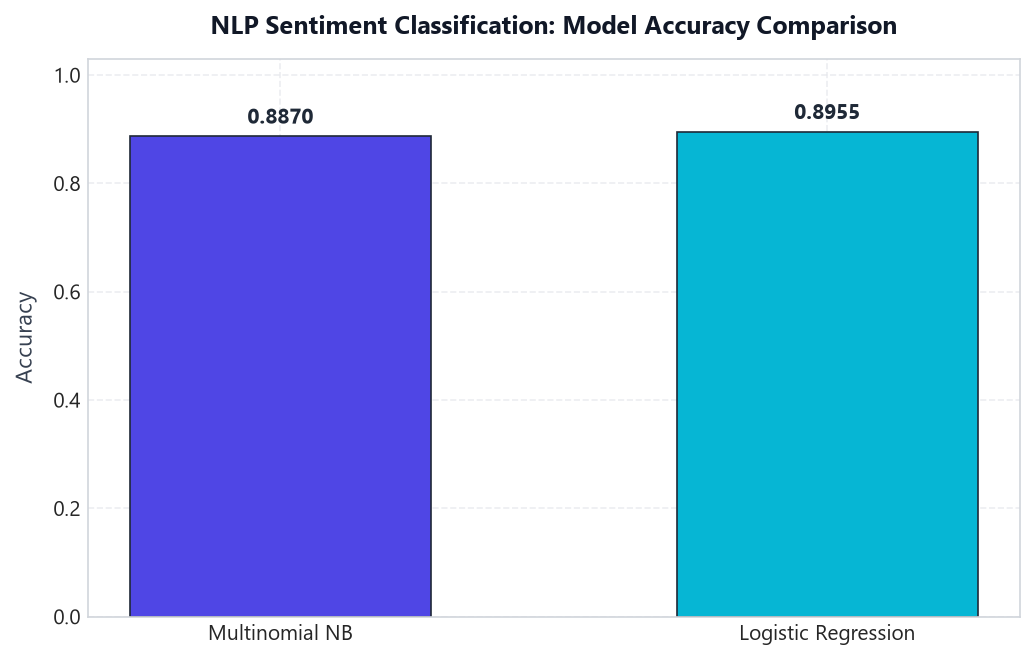

In [7]:
# Confusion Matrices
for name, m in results.items():
    fig = plot_confusion_matrix(
        cm=m['confusion_matrix'],
        class_names=['Negative', 'Positive'],
        title=f"Sentiment Matrix: {name.replace('_', ' ').title()}"
    )
    plt.show()

# Model Comparison
fig_comp = plot_model_comparison(
    models_dict={
        'Multinomial NB': results['multinomial_nb']['accuracy'],
        'Logistic Regression': results['logistic_regression']['accuracy']
    },
    metric_name='Accuracy',
    title='NLP Sentiment Classification: Model Accuracy Comparison'
)
plt.show()


### 8. Interactive Prediction Helper & Probability Calibration Caveat
We test custom real-world reviews across diverse sentiment contexts:
- Enthusiastic praise
- Direct negative product failure
- Subtle critique
- Negation handling ("Not bad at all")
- Sarcasm / Mixed reaction


In [8]:
custom_reviews = [
    "This product is absolutely wonderful! It exceeded all my expectations and arrived quickly.",
    "Terrible quality, broke after two days of light use. Customer service was completely unhelpful.",
    "It is decent for the price, but nothing to get overly excited about.",
    "Not bad at all, works much better than the previous brand I purchased.",
    "I wanted to love this, but it completely failed to perform as advertised. Waste of money."
]

print("Custom Review Inference Results (Logistic Regression Pipeline):\n")
for idx, text in enumerate(custom_reviews, 1):
    res = predict_sentiment(models['logistic_regression'], text)
    print(f"Review {idx}: \"{text}\"")
    print(f" -> Predicted Sentiment: {res['predicted_sentiment'].upper()}")
    print(f" -> Probabilities: Positive={res['probabilities']['positive']:.2%}, Negative={res['probabilities']['negative']:.2%}")
    print()
print("Probability Calibration Disclaimer:")
print(res['calibration_note'])


Custom Review Inference Results (Logistic Regression Pipeline):

Review 1: "This product is absolutely wonderful! It exceeded all my expectations and arrived quickly."
 -> Predicted Sentiment: POSITIVE
 -> Probabilities: Positive=89.58%, Negative=10.42%

Review 2: "Terrible quality, broke after two days of light use. Customer service was completely unhelpful."
 -> Predicted Sentiment: POSITIVE
 -> Probabilities: Positive=55.67%, Negative=44.33%

Review 3: "It is decent for the price, but nothing to get overly excited about."
 -> Predicted Sentiment: POSITIVE
 -> Probabilities: Positive=72.74%, Negative=27.26%

Review 4: "Not bad at all, works much better than the previous brand I purchased."
 -> Predicted Sentiment: POSITIVE
 -> Probabilities: Positive=52.05%, Negative=47.95%

Review 5: "I wanted to love this, but it completely failed to perform as advertised. Waste of money."
 -> Predicted Sentiment: NEGATIVE
 -> Probabilities: Positive=46.29%, Negative=53.71%

Probability Calibration

### 9. Statistical & Engineering Takeaways
1. **Discriminative Superiority**: Logistic Regression consistently outperforms Naive Bayes (higher Accuracy and Macro F1) because it does not assume feature conditional independence, learning nuanced word weights.
2. **N-gram Advantage**: Utilizing bigrams (`ngram_range=(1,2)`) enables the pipeline to capture two-word sentiment modifiers such as "not bad", "highly recommend", and "waste of".
3. **Probability Caveat**: Naive Bayes probabilities tend to be overly confident (pushing toward 0 or 1) due to independent likelihood multiplication, whereas Logistic Regression yields better-separated decision scores.
